# 0. Some technical steps

In this notebook we work with daily historical sales data. Our dataset consists of the following columns:

1) shop_id - unique identifier of a shop
2) item_id - unique identifier of a product
3) item_category_id - unique identifier of item category
4) item_cnt_day - number of products sold. We are predicting a monthly amount of this measure
5) item_price - current price of an item
6) date - date in format dd/mm/yyyy
7) date_block_num - a consecutive month number, used for convenience. January 2013 is 0, February 2013 is 1,..., October 2015 is 33
8) item_name - name of item
9) shop_name - name of shop
10) item_category_name - name of item category

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

train = pd.read_csv("data/sales_train.csv")
items = pd.read_csv("data/items.csv")
shops = pd.read_csv("data/shops.csv")
categories = pd.read_csv("data/item_categories.csv")
result = pd.merge(train, shops, how="left", on=["shop_id"])
result = pd.merge(result, items, how="left", on=["item_id"])
train_result = pd.merge(result, categories, how="left", on=["item_category_id"])
train_result.head()

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
0,02.01.2013,0,59,22154,999.00,1.0,"Ярославль ТЦ ""Альтаир""",ЯВЛЕНИЕ 2012 (BD),37,Кино - Blu-Ray
1,03.01.2013,0,25,2552,899.00,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
2,05.01.2013,0,25,2552,899.00,-1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
3,06.01.2013,0,25,2554,1709.05,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE Who Do You Think We Are LP,58,Музыка - Винил
4,15.01.2013,0,25,2555,1099.00,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE 30 Very Best Of 2CD (Фирм.),56,Музыка - CD фирменного производства


In [2]:
train_result.info()

<class 'pandas.DataFrame'>
RangeIndex: 2935849 entries, 0 to 2935848
Data columns (total 10 columns):
 #   Column              Dtype  
---  ------              -----  
 0   date                str    
 1   date_block_num      int64  
 2   shop_id             int64  
 3   item_id             int64  
 4   item_price          float64
 5   item_cnt_day        float64
 6   shop_name           str    
 7   item_name           str    
 8   item_category_id    int64  
 9   item_category_name  str    
dtypes: float64(2), int64(4), str(4)
memory usage: 224.0 MB


In [3]:
test = pd.read_csv("data/test.csv")
result = pd.merge(test, shops, how="left", on=["shop_id"])
result = pd.merge(result, items, how="left", on=["item_id"])
test_result = pd.merge(result, categories, how="left", on=["item_category_id"])
test_result.head()

,ID,shop_id,item_id,shop_name,item_name,item_category_id,item_category_name
0,0,5,5037,"Вологда ТРЦ ""Мармелад""","NHL 15 [PS3, русские субтитры]",19,Игры - PS3
1,1,5,5320,"Вологда ТРЦ ""Мармелад""",ONE DIRECTION Made In The A.M.,55,Музыка - CD локального производства
2,2,5,5233,"Вологда ТРЦ ""Мармелад""","Need for Speed Rivals (Essentials) [PS3, русск...",19,Игры - PS3
3,3,5,5232,"Вологда ТРЦ ""Мармелад""","Need for Speed Rivals (Classics) [Xbox 360, ру...",23,Игры - XBOX 360
4,4,5,5268,"Вологда ТРЦ ""Мармелад""","Need for Speed [PS4, русская версия]",20,Игры - PS4


In [4]:
test_result.info()

<class 'pandas.DataFrame'>
RangeIndex: 214200 entries, 0 to 214199
Data columns (total 7 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   ID                  214200 non-null  int64
 1   shop_id             214200 non-null  int64
 2   item_id             214200 non-null  int64
 3   shop_name           214200 non-null  str  
 4   item_name           214200 non-null  str  
 5   item_category_id    214200 non-null  int64
 6   item_category_name  214200 non-null  str  
dtypes: int64(4), str(3)
memory usage: 11.4 MB


# 1. Completeness 

In [5]:
print(f"number of missing data in test dataset: {train_result.isnull().sum().sum()}")

number of missing data in test dataset: 0


In [6]:
print(f"number of missing data in test dataset: {test_result.isnull().sum().sum()}")

number of missing data in test dataset: 0


In [7]:
# Unique counts for several columns at once
print(f"number of unique items: {items['item_name'].nunique()}")
print(f"number of unique items in train data: {train_result['item_name'].nunique()}")
print(f"number of unique shops: {shops['shop_name'].nunique()}")
print(f"number of unique shops in train data: {train_result['shop_name'].nunique()}")

number of unique items: 22170
number of unique items in train data: 21807
number of unique shops: 60
number of unique shops in train data: 60


In total 363 items were never sold, all shops are present in the training dataset, both training and test datasets don't have missing data

In [8]:
# Items that exist in the catalogue but never appear in train
never_sold = set(items["item_id"]) - set(train["item_id"])
print("never sold:", len(never_sold))

# How many of them are in test (items and rows)
in_test = never_sold & set(test["item_id"])
print("of them in test:", len(in_test))
print("test rows with such items:", test["item_id"].isin(never_sold).sum())

never sold: 363
of them in test: 363
test rows with such items: 15246


# 2. Consistency 

In [9]:
# Every foreign key must exist in the corresponding reference table
checks = {
    "train.shop_id and shops": ~train["shop_id"].isin(shops["shop_id"]),
    "train.item_id and items": ~train["item_id"].isin(items["item_id"]),
    "test.shop_id and shops": ~test["shop_id"].isin(shops["shop_id"]),
    "test.item_id and items": ~test["item_id"].isin(items["item_id"]),
    "items.item_category_id and categories": ~items["item_category_id"].isin(
        categories["item_category_id"]
    ),
}
for name, mask in checks.items():
    print(f"{name}: unmached rows = {mask.sum()}")

train.shop_id and shops: unmached rows = 0
train.item_id and items: unmached rows = 0
test.shop_id and shops: unmached rows = 0
test.item_id and items: unmached rows = 0
items.item_category_id and categories: unmached rows = 0


In [10]:
# Row count must not change after join
print("train rows equal:", len(train) == len(train_result))
print("test rows equal:", len(test) == len(test_result))

# No missing values after join
print("train NaN after join:", train_result.isnull().sum().sum())
print("test NaN after join:", test_result.isnull().sum().sum())

train rows equal: True
test rows equal: True
train NaN after join: 0
test NaN after join: 0


In [11]:
def check_date_block_num(df: pd.DataFrame) -> pd.DataFrame:
    """Compute date_block_num from date and compare it with the existing column."""
    d = pd.to_datetime(df["date"], format="%d.%m.%Y")
    # 0 = January 2013, 1 = February 2013, ...
    expected = (d.dt.year - 2013) * 12 + d.dt.month - 1
    mismatch = df.loc[df["date_block_num"] != expected, ["date", "date_block_num"]]
    mismatch = mismatch.assign(expected=expected[mismatch.index])
    print(f"mismatches: {len(mismatch)} of {len(df)}")
    return mismatch


mismatch = check_date_block_num(train_result)

mismatches: 0 of 2935849


In summary, the referential integrity of the keys between train and test is preserved, no missing values appear after the joins, and each `date_block_num` maps uniquely to its own (month, year) pair.

# 3. Timeliness 

In [12]:
# Date range of the training data
d = pd.to_datetime(train_result["date"], format="%d.%m.%Y")
print("from", d.min().date(), "to", d.max().date())

# Data volume per month block
per_block = train_result.groupby("date_block_num").agg(
    rows=("item_id", "size"),  # number of sales records
    shops=("shop_id", "nunique"),  # active shops
    items=("item_id", "nunique"),  # sold items
    items_sold=("item_cnt_day", "sum"),  # total units sold
)
print(per_block)

from 2013-01-01 to 2015-10-31
                  rows  shops  items  items_sold
date_block_num                                  
0               115690     45   8115    131479.0
1               108613     46   8168    128090.0
2               121347     46   8302    147142.0
3                94109     46   8145    107190.0
4                91759     45   8339    106970.0
5               100403     46   8478    125381.0
6               100548     46   8405    116966.0
7               104772     45   8031    125291.0
8                96137     45   7876    133332.0
9                94202     46   8039    127541.0
10               96736     45   8089    130009.0
11              143246     46   8474    183342.0
12               99349     46   7551    116899.0
13               89830     46   7134    109687.0
14               92733     48   7142    115297.0
15               77906     49   6774     96556.0
16               78529     49   6685     97790.0
17               82408     49   6681   

There is no missing months and the number od data is enought for predicting for november 2015

# 4. Accuracy 

In [13]:
train_result.describe().round(2)

,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_category_id
count,2935849.00,2935849.00,2935849.00,2935849.00,2935849.00,2935849.0
mean,14.57,33.00,10197.23,890.85,1.24,40.0
std,9.42,16.23,6324.30,1729.80,2.62,17.1
min,0.00,0.00,0.00,-1.00,-22.00,0.0
25%,7.00,22.00,4476.00,249.00,1.00,28.0
50%,14.00,31.00,9343.00,399.00,1.00,40.0
75%,23.00,47.00,15684.00,999.00,1.00,55.0
max,33.00,59.00,22169.00,307980.00,2169.00,83.0


In [14]:
test_result.describe().round(2)

,ID,shop_id,item_id,item_category_id
count,214200.00,214200.00,214200.00,214200.00
mean,107099.50,31.64,11019.40,46.31
std,61834.36,17.56,6252.64,16.72
min,0.00,2.00,30.00,0.00
25%,53549.75,16.00,5381.50,37.00
50%,107099.50,34.50,11203.00,43.00
75%,160649.25,47.00,16071.50,58.00
max,214199.00,59.00,22167.00,83.00


## 4.1 Missing values

Data containd no Nan, but let's look into negative values in item_price and item_cnt_day

In [15]:
train_result[train_result["item_price"] < 0]

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
484683,15.05.2013,4,32,2973,-1.0,1.0,"Москва ТЦ ""Серебряный Дом""","DmC Devil May Cry [PS3, русские субтитры]",19,Игры - PS3


In [16]:
print(train_result[train_result["item_cnt_day"] < 0].shape)
# percentage of negative values in item_cnt_day
print(
    train_result[train_result["item_cnt_day"] < 0].shape[0]
    / train_result.shape[0]
    * 100
)

(7356, 10)
0.2505578454477734


In [24]:
train_result[train_result["item_cnt_day"] < 0].head(5)

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
2,05.01.2013,0,25,2552,899.0,-1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
148,23.01.2013,0,25,2321,999.0,-1.0,"Москва ТРК ""Атриум""",Call of Duty: Black Ops II. Расширенное издани...,28,Игры PC - Дополнительные издания
175,07.01.2013,0,25,2199,1449.0,-1.0,"Москва ТРК ""Атриум""",COLDPLAY Mylo Xyloto LP,58,Музыка - Винил
807,02.01.2013,0,25,2330,599.0,-1.0,"Москва ТРК ""Атриум""","Call of Duty: Black Ops [PC, Jewel, русская ве...",30,Игры PC - Стандартные издания
1041,13.01.2013,0,25,5034,1989.0,-1.0,"Москва ТРК ""Атриум""","NHL 13 [Xbox 360, русская документация]",23,Игры - XBOX 360


In [25]:
train_result[train_result["item_id"] == 2552]

,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,shop_name,item_name,item_category_id,item_category_name
1,03.01.2013,0,25,2552,899.0,1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
2,05.01.2013,0,25,2552,899.0,-1.0,"Москва ТРК ""Атриум""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
375824,25.04.2013,3,6,2552,949.0,1.0,"Воронеж (Плехановская, 13)",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
419930,25.04.2013,3,30,2552,949.0,1.0,"Москва ТЦ ""Перловский""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
523067,24.05.2013,4,4,2552,949.0,1.0,"Волжский ТЦ ""Волга Молл""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
531235,14.05.2013,4,6,2552,949.0,-1.0,"Воронеж (Плехановская, 13)",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
679741,14.07.2013,6,22,2552,949.0,1.0,Москва Магазин С21,DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
1723811,28.06.2014,17,28,2552,949.0,1.0,"Москва ТЦ ""МЕГА Теплый Стан"" II",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил
2648872,27.05.2015,28,50,2552,949.0,1.0,"Тюмень ТЦ ""Гудвин""",DEEP PURPLE The House Of Blue Light LP,58,Музыка - Винил


7356 negative values are founded in training dataset, these are returns. Negative price will be dropped

## 4.2 Numberical values, statistics

In [93]:
# Numeric columns only; drop ID-like columns that are really categorical
num = train_result.select_dtypes("number").drop(
    columns=["shop_id", "item_id", "item_category_id"]
)

stats = num.agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
stats = stats.join(num.quantile([0.01, 0.25, 0.75, 0.99]).T.add_prefix("q"))
stats["negative"] = (num < 0).sum()

stats.style.format("{:,.2f}")

,count,mean,median,std,min,max,skew,kurt,q0.01,q0.25,q0.75,q0.99,negative
date_block_num,"2,935,849.00",14.57,14.00,9.42,0.00,33.00,0.20,-1.08,0.00,7.00,23.00,33.00,0.00
item_price,"2,935,849.00",890.85,399.00,"1,729.80",-1.00,"307,980.00",10.75,445.53,5.00,249.00,999.00,"5,999.00",1.00
item_cnt_day,"2,935,849.00",1.24,1.00,2.62,-22.00,"2,169.00",272.83,"177,478.10",1.00,1.00,1.00,5.00,"7,356.00"


item_price and especially item_cnt_day are extremely right-skewed with heavy outliers. These variables should be cleaned (drop the invalid price, clip or remove outliers) before modeling.

### 4.3 Dead columns

In [94]:
id_cols = ["shop_id", "item_id", "item_category_id"]

rows = []
for c in train_result.columns.drop(id_cols):
    counts = train_result[c].value_counts(
        normalize=True
    )  # sorted from most to least frequent
    rows.append(
        {
            "column": c,
            "n_unique": len(counts),
            "top_value": counts.index[0],
            "top_value_share": counts.iloc[0],
        }
    )
summary = pd.DataFrame(rows).set_index("column")
display(summary.style.format({"top_value_share": "{:.1%}"}))

,n_unique,top_value,top_value_share
column,,,
date,1034,28.12.2013,0.3%
date_block_num,34,11,4.9%
item_price,19993,299.000000,9.9%
item_cnt_day,198,1.000000,89.6%
shop_name,60,"Москва ТЦ ""Семеновский""",8.0%
item_name,21807,Фирменный пакет майка 1С Интерес белый (34*42) 45 мкм,1.1%
item_category_name,84,Кино - DVD,19.2%


About 90% of `item_cnt_day` values equal 1, so the target is concentrated on small values; no column is constant and no other column has a dominant value. 

## 4.4 Outliers

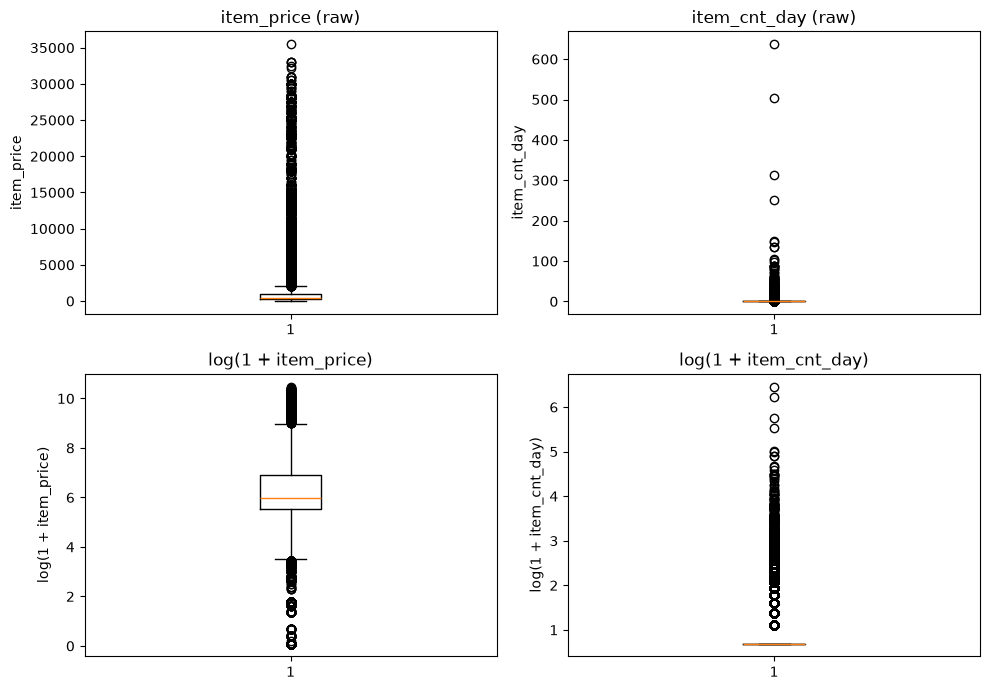

In [95]:
continuous_feature = ["item_price", "item_cnt_day"]

# boxplots
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for col, feature in enumerate(continuous_feature):
    # log needs positive values; sample to keep the plot fast (2.9M rows)
    data = train_result.loc[train_result[feature] > 0, feature]
    sample = data.sample(200_000, random_state=42)

    axes[0, col].boxplot(sample)
    axes[0, col].set(title=f"{feature} (raw)", ylabel=feature)

    axes[1, col].boxplot(np.log1p(sample))
    axes[1, col].set(title=f"log(1 + {feature})", ylabel=f"log(1 + {feature})")
plt.tight_layout()
plt.show()


# Statistical detection
def outlier_report(series, feature):
    s = series.dropna()

    # IQR: outside [Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    # Z-score: more than 3 standard deviations away from the mean
    z_low, z_high = s.mean() - 3 * s.std(), s.mean() + 3 * s.std()

    rows = [
        ("IQR", iqr_low, iqr_high, ((s < iqr_low) | (s > iqr_high)).sum()),
        ("Z-score", z_low, z_high, ((s < z_low) | (s > z_high)).sum()),
    ]
    out = pd.DataFrame(
        rows, columns=["Method", "Lower bound", "Upper bound", "Outliers (count)"]
    )
    out["Outliers (share)"] = out["Outliers (count)"] / len(s)
    out.insert(0, "Feature", feature)
    return out


report = pd.concat(
    [outlier_report(train_result[f], f) for f in continuous_feature]
).set_index(["Feature", "Method"])

display(
    report.style.format(
        {
            "Lower bound": "{:,.1f}",
            "Upper bound": "{:,.1f}",
            "Outliers (count)": "{:,.0f}",
            "Outliers (share)": "{:.1%}",
        }
    )
)

The IQR flags 8.8% of `item_price` values and the Z-score only 1.0%, because the distribution is right-skewed: IQR labels part of the natural tail as outliers, while extreme values inflate the standard deviation.For item_cnt_day the IQR rule does not work properly: most values equal 1, so the IQR is 0 and every other value is flagged as an outlier. So the Z-score is more informative. Extreme outliers will be dropped before modeling part.

In [103]:
show_cols = ["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day"]


def show_top(df: pd.DataFrame, col: str, n: int = 10) -> None:
    top = df.nlargest(n, col)[show_cols].copy()
    top["item_name"] = top["item_name"].str.slice(0, 40)
    top = top.reset_index(drop=True)
    top.index = top.index + 1
    top.index.name = "rank"

    print(f"\nTop {n} by {col}")
    display(top.style.format({"item_price": "{:,.2f}", "item_cnt_day": "{:,.0f}"}))


show_top(train_result, "item_price")
show_top(train_result, "item_cnt_day")


Top 10 by item_price


,date,shop_id,item_id,item_name,item_price,item_cnt_day
rank,,,,,,
1,13.12.2013,12,6066,Radmin 3 - 522 лиц.,"307,980.00",1
2,17.09.2013,12,11365,Доставка (EMS),"59,200.00",1
3,20.03.2014,25,13199,Коллекционные шахматы (Властелин Колец),"50,999.00",1
4,29.01.2015,12,7241,UserGate Proxy & Firewall 6.X с модулем,"49,782.00",1
5,23.10.2015,42,13403,"Комплект ""Microsoft Xbox One 1TB Limite","42,990.00",1
6,29.10.2015,12,13403,"Комплект ""Microsoft Xbox One 1TB Limite","42,990.00",1
7,20.10.2015,3,13403,"Комплект ""Microsoft Xbox One 1TB Limite","42,990.00",1
8,20.10.2015,22,13403,"Комплект ""Microsoft Xbox One 1TB Limite","42,990.00",1
9,24.10.2013,12,7238,UserGate Proxy & Firewall 6.X до 100 сес,"42,000.00",1



Top 10 by item_cnt_day


,date,shop_id,item_id,item_name,item_price,item_cnt_day
rank,,,,,,
1,28.10.2015,12,11373,Доставка до пункта выдачи (Boxberry),0.91,"2,169"
2,15.01.2015,12,20949,Фирменный пакет майка 1С Интерес белый (,4.00,"1,000"
3,30.09.2015,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (с","1,692.53",669
4,30.09.2015,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (с","1,702.83",637
5,14.04.2015,12,3731,"Grand Theft Auto V [PC, русские субтитры","1,904.55",624
6,19.05.2015,12,11373,Доставка до пункта выдачи (Boxberry),155.19,539
7,29.09.2015,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (с","1,500.00",533
8,02.10.2014,12,9242,"Билет ""ИгроМир 2014"" (на один день (отде","1,500.00",512
9,09.10.2014,55,19437,"Средиземье: Тени Мордора [PC, Цифровая в",899.00,508


Actually some outliers make sense and there is no need to  delete them. However, "Radmin 3 - 522 лиц" and all delivery will be deleted

## 4.5 Categorical Variables

### 4.5.1 Cardinality check

In [96]:
import matplotlib.pyplot as plt
import pandas as pd

# Categorical features: text columns + ID columns (numeric, but categorical by meaning)
id_cols = ["shop_id", "item_id", "item_category_id"]
categorical_features = (
    train_result.select_dtypes("object").columns.drop("date").tolist() + id_cols
)

# Cardinality: number of categories and share of the most frequent one
cardinality = pd.DataFrame(
    {
        "n_categories": train_result[categorical_features].nunique(),
        "top_category_share": [
            train_result[f].value_counts(normalize=True).iloc[0]
            for f in categorical_features
        ],
    }
).sort_values("n_categories")
cardinality.style.format({"top_category_share": "{:.1%}"})

C:\Users\pikil\AppData\Local\Temp\ipykernel_26672\239467273.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_result.select_dtypes("object").columns.drop("date").tolist() + id_cols


,n_categories,top_category_share
shop_name,60,8.0%
shop_id,60,8.0%
item_category_name,84,19.2%
item_category_id,84,19.2%
item_name,21807,1.1%
item_id,21807,1.1%


Shops and item categories have low cardinality and can be encoded directly, while items have very high cardinality. No single category dominate. Names and IDs have identical counts, so each name duplicates its ID and only one of them should be used as a feature.

### 4.5.2 Duplicates check

In [97]:
from difflib import SequenceMatcher
from itertools import combinations

# Keys of the reference tables must be unique, otherwise merges duplicate rows
refs = [
    ("shops", shops, "shop_id", "shop_name"),
    ("items", items, "item_id", "item_name"),
    ("categories", categories, "item_category_id", "item_category_name"),
]
for label, ref, id_col, name_col in refs:
    n_dup_ids = ref[id_col].duplicated().sum()
    n_dup_names = ref[name_col].str.lower().str.strip().duplicated().sum()
    print(
        f"{label}: duplicated IDs = {n_dup_ids}, exact duplicated names = {n_dup_names}"
    )

# Near-duplicate names under different IDs (candidates for manual review)
for label, ref, id_col, name_col, threshold in [
    ("shops", shops, "shop_id", "shop_name", 0.85),
    ("categories", categories, "item_category_id", "item_category_name", 0.9),
]:
    names = ref.set_index(id_col)[name_col]
    clean = names.str.lower().str.strip("! ")
    rows = []
    for a, b in combinations(names.index, 2):
        ratio = SequenceMatcher(None, clean[a], clean[b]).ratio()
        if ratio > threshold:
            rows.append((a, b, round(ratio, 2), names[a], names[b]))
    print(f"\nSimilar {label}:")
    display(
        pd.DataFrame(rows, columns=["id_a", "id_b", "similarity", "name_a", "name_b"])
    )

# date must agree with date_block_num (0 = January 2013)
dates = pd.to_datetime(train_result["date"], format="%d.%m.%Y")
expected_block = (dates.dt.year - 2013) * 12 + dates.dt.month - 1
print(
    "Rows where date and date_block_num disagree:",
    (expected_block != train_result["date_block_num"]).sum(),
)

shops: duplicated IDs = 0, exact duplicated names = 0
items: duplicated IDs = 0, exact duplicated names = 59
categories: duplicated IDs = 0, exact duplicated names = 0

Similar shops:


,id_a,id_b,similarity,name_a,name_b
0,0,57,0.90,"!Якутск Орджоникидзе, 56 фран","Якутск Орджоникидзе, 56"
1,1,58,0.90,"!Якутск ТЦ ""Центральный"" фран","Якутск ТЦ ""Центральный"""
2,10,11,0.96,Жуковский ул. Чкалова 39м?,Жуковский ул. Чкалова 39м²
3,23,24,0.94,"Москва ТК ""Буденовский"" (пав.А2)","Москва ТК ""Буденовский"" (пав.К7)"
4,39,40,0.88,"РостовНаДону ТРК ""Мегацентр Горизонт""","РостовНаДону ТРК ""Мегацентр Горизонт"" Островной"



Similar categories:


,id_a,id_b,similarity,name_a,name_b
0,1,2,0.94,Аксессуары - PS2,Аксессуары - PS3
1,1,3,0.94,Аксессуары - PS2,Аксессуары - PS4
2,1,4,0.94,Аксессуары - PS2,Аксессуары - PSP
3,2,3,0.94,Аксессуары - PS3,Аксессуары - PS4
4,2,4,0.94,Аксессуары - PS3,Аксессуары - PSP
5,3,4,0.94,Аксессуары - PS4,Аксессуары - PSP
6,10,11,0.95,Игровые консоли - PS2,Игровые консоли - PS3
7,10,12,0.95,Игровые консоли - PS2,Игровые консоли - PS4
8,10,13,0.95,Игровые консоли - PS2,Игровые консоли - PSP
9,11,12,0.95,Игровые консоли - PS3,Игровые консоли - PS4


Rows where date and date_block_num disagree: 0


In the results we found 59 exact duplicates of item names. We also found 3 pairs of duplicated shops (0/57, 1/58, 10/11) with the same address and a different franchise marker or typo, which will be merged. The other similar shop names (23/24, 39/40) are different pavilions or branches, and all similar category names differ by platform or format (PS2/PS3/PS4/PSP, Blu-Ray/3D/4K, MAC/PC), so there are no duplicated categories.

# 5. Validity 

In [98]:
print("train_result:")
print(train_result.dtypes)

print("\ntest_result:")
print(test_result.dtypes)

train_result:
date                      str
date_block_num          int64
shop_id                 int64
item_id                 int64
item_price            float64
item_cnt_day          float64
shop_name                 str
item_name                 str
item_category_id        int64
item_category_name        str
dtype: object

test_result:
ID                    int64
shop_id               int64
item_id               int64
shop_name               str
item_name               str
item_category_id      int64
item_category_name      str
dtype: object


All features have en expected type of data

# 6. ETL

In [109]:
# Settings taken from the analysis above
SHOP_MERGE = {
    0: 57,
    1: 58,
    10: 11,
}  # duplicated shops (same address, different marker / typo)
MAX_PRICE = 100_000  # removes outliers
TARGET_CLIP = (0, 20)  # true target is clipped into [0, 20]
TEST_BLOCK = 34  # forecast month: November 2015

shop_names = shops.set_index("shop_id")["shop_name"]


def merge_duplicate_shops(df: pd.DataFrame) -> pd.DataFrame:
    """Replace duplicated shop ids and make shop_name consistent with the new ids."""
    df = df.copy()
    df["shop_id"] = df["shop_id"].replace(SHOP_MERGE)
    df["shop_name"] = df["shop_id"].map(shop_names)
    return df


def etl_train(df: pd.DataFrame) -> pd.DataFrame:
    n_before = len(df)

    # Transform: shops and dates
    df = merge_duplicate_shops(df)
    df["date"] = pd.to_datetime(df["date"], format="%d.%m.%Y")

    # Only invalid or extreme prices are removed
    bad_price = (df["item_price"] <= 0) | (df["item_price"] >= MAX_PRICE)
    print(f"invalid or extreme price: {bad_price.sum():,}")
    df = df[~bad_price].copy()

    # Calendar features
    df["day"] = df["date"].dt.day
    df["month"] = df["date"].dt.month
    df["year"] = df["date"].dt.year
    df["quarter"] = df["date"].dt.quarter
    df["weekday"] = df["date"].dt.day_of_week  # 0 = Monday
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)

    # Data types
    df = df.astype(
        {
            "date_block_num": "int8",
            "shop_id": "int8",
            "item_category_id": "int8",
            "item_id": "int32",
            "item_price": "float32",
            "item_cnt_day": "float32",
            "day": "int8",
            "month": "int8",
            "year": "int16",
            "quarter": "int8",
            "weekday": "int8",
            "is_weekend": "int8",
        }
    )

    print(f"train: removed {n_before - len(df):,} of {n_before:,} rows in total")
    return df.reset_index(drop=True)


def etl_test(df: pd.DataFrame) -> pd.DataFrame:
    # Test rows are never removed: a prediction is needed for every (shop, item) pair
    df = merge_duplicate_shops(df)

    # The test set is one month: November 2015
    df["date_block_num"] = TEST_BLOCK
    df["year"] = 2015
    df["month"] = 11
    df["quarter"] = 4

    return df.astype(
        {
            "ID": "int32",
            "shop_id": "int8",
            "item_id": "int32",
            "item_category_id": "int8",
            "date_block_num": "int8",
            "year": "int16",
            "month": "int8",
            "quarter": "int8",
        }
    )


def make_monthly_target(df: pd.DataFrame) -> pd.DataFrame:
    """Monthly target per (month, shop, item): sum of daily sales, clipped into [0, 20]."""
    monthly = (
        df.groupby(["date_block_num", "shop_id", "item_id"], as_index=False)[
            "item_cnt_day"
        ]
        .sum()
        .rename(columns={"item_cnt_day": "item_cnt_month"})
    )
    monthly["item_cnt_month"] = monthly["item_cnt_month"].clip(*TARGET_CLIP)
    return monthly


train_clean = etl_train(train_result)
test_clean = etl_test(test_result)

# Quick checks after ETL
print("train shape:", train_clean.shape, "| test shape:", test_clean.shape)
print("unique shops in train (expected 57):", train_clean["shop_id"].nunique())
print(
    "test shops all present in train:",
    set(test_clean["shop_id"]) <= set(train_clean["shop_id"]),
)

# Load: save cleaned data
train_clean.to_csv("data/train_clean.csv", index=False)
test_clean.to_csv("data/test_clean.csv", index=False)

invalid or extreme price: 2
train: removed 2 of 2,935,849 rows in total
train shape: (2935847, 16) | test shape: (214200, 11)
unique shops in train (expected 57): 57
test shops all present in train: True
